Komórka 1: przygotowanie

In [21]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", message=".*inplace keyword.*")
sys.path.append(str(Path.cwd().parent / "src"))

from db import get_engine
from evaluation import (all_stocks, performance, run_strategy, top_k, top_k_per_sector,
                        walk_forward_predictions)
from features import build_dataset, training_rows

engine = get_engine()
data = training_rows(build_dataset(engine))
preds = walk_forward_predictions(data, lambda: LogisticRegression(max_iter=1000))

print("Okres testowy:", preds["date"].min().date(), "-", preds["date"].max().date(),
      f"({preds['date'].nunique()} miesięcy)")
print("AUC (kontrola zgodności z notatnikiem 02):",
      round(preds.groupby(preds["date"].dt.year).apply(lambda g: roc_auc_score(g["label"], g["score"])).mean(), 4))

Okres testowy: 2016-01-31 - 2026-09-30 (129 miesięcy)
AUC (kontrola zgodności z notatnikiem 02): 0.521


Komórka 2: strategie

In [22]:
universe = pd.read_csv(Path.cwd().parent / "config" / "universe.csv")
sectors = dict(zip(universe["ticker"], universe["sector"]))
wig20_members = set(universe.loc[universe["index"] == "WIG20", "ticker"])

strategies = {
    "Model: top 10": run_strategy(preds, top_k(10)),
    "Model: top 10, maks. 2 na sektor": run_strategy(preds, top_k_per_sector(10, sectors)),
    "Równe wagi (wszystkie spółki)": run_strategy(preds, all_stocks),
}
net = pd.DataFrame({name: s["net"] for name, s in strategies.items()})
net.tail(3).round(4)


,Model: top 10,"Model: top 10, maks. 2 na sektor",Równe wagi (wszystkie spółki)
date,,,
2026-08-31,0.0434,0.0434,0.0268
2026-09-30,0.0361,0.0434,0.0144
2026-10-31,0.0119,0.0125,-0.0062


In [23]:
print("Miesięcy w net po komórce 2:", len(net))

Miesięcy w net po komórce 2: 129


Komórka 3: indeks WIG20 jako punkt odniesienia

In [28]:
import yfinance as yf


def monthly_returns(symbol: str) -> pd.Series | None:
    """Miesięczne stopy zwrotu z Yahoo albo None, gdy brak wieloletniej historii."""
    df = yf.download(symbol, start="2015-12-01", auto_adjust=True, progress=False)
    if len(df) < 250:  # potrzebujemy co najmniej roku notowań, a nie pojedynczego kursu
        return None
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    close = df["Close"]
    if close.index.tz is not None:
        close.index = close.index.tz_localize(None)
    returns = close.resample("ME").last().pct_change()
    returns.index = returns.index.to_period("M")
    print(f"{symbol}: notowania od {close.index.min().date()} do {close.index.max().date()}")
    return returns


benchmark, symbol = None, None
for candidate in ["WIG20TR.WA", "ETFBW20TR.WA", "WIG20.WA", "^WIG20"]:
    benchmark = monthly_returns(candidate)
    if benchmark is not None:
        symbol = candidate
        break
    print(f"{candidate}: brak historii")

if benchmark is not None:
    net[f"WIG20 ({symbol})"] = benchmark.reindex(net.index.to_period("M")).to_numpy()
    print("Miesięcy bez danych benchmarku:", net.iloc[:, -1].isna().sum())
else:
    print("Brak historii WIG20 w Yahoo - zastępczo: spółki z obecnego WIG20 po równo")
    net["WIG20 (obecny skład, równe wagi)"] = run_strategy(
        preds, lambda m: m.index.intersection(list(wig20_members)))["net"]

nbenchmark_cols = [c for c in net.columns if c.startswith("WIG20")]
common = net.dropna()
print(f"Cały okres: {net.index.min():%Y-%m} – {net.index.max():%Y-%m} ({len(net)} mies.)")
print(f"Wspólny okres z WIG20: {common.index.min():%Y-%m} – {common.index.max():%Y-%m} ({len(common)} mies.)")

WIG20TR.WA: brak historii
ETFBW20TR.WA: notowania od 2019-01-07 do 2026-11-05
Miesięcy bez danych benchmarku: 36
Cały okres: 2016-02 – 2026-10 (129 mies.)
Wspólny okres z WIG20: 2019-02 – 2026-10 (93 mies.)


Komórka 4: wyniki

In [30]:
benchmark_cols = [c for c in net.columns if c.startswith("WIG20")]
common = net.dropna()
print(f"Cały okres: {net.index.min():%Y-%m} – {net.index.max():%Y-%m} ({len(net)} mies.)")
print(f"Wspólny okres z WIG20: {common.index.min():%Y-%m} – {common.index.max():%Y-%m} ({len(common)} mies.)")

PCT_COLUMNS = ["Roczna stopa zwrotu", "Zmienność roczna", "Maks. obsunięcie", "Miesięcy na plusie"]


def results_table(df: pd.DataFrame):
    table = pd.DataFrame({name: performance(df[name]) for name in df.columns}).T
    return table.style.format("{:.1%}", subset=PCT_COLUMNS).format("{:.2f}", subset=["Sharpe (rf = 0)"])


print("Cały okres (2016–2026), bez benchmarku WIG20:")
display(results_table(net.drop(columns=benchmark_cols)))

print("Wspólny okres z WIG20TR:")
display(results_table(common))

Cały okres: 2016-02 – 2026-10 (129 mies.)
Wspólny okres z WIG20: 2019-02 – 2026-10 (93 mies.)
Cały okres (2016–2026), bez benchmarku WIG20:


,Roczna stopa zwrotu,Zmienność roczna,Sharpe (rf = 0),Maks. obsunięcie,Miesięcy na plusie
Model: top 10,29.0%,20.7%,1.35,-43.0%,65.1%
"Model: top 10, maks. 2 na sektor",31.2%,21.0%,1.41,-33.0%,65.1%
Równe wagi (wszystkie spółki),21.5%,19.0%,1.13,-29.6%,67.4%


Wspólny okres z WIG20TR:


,Roczna stopa zwrotu,Zmienność roczna,Sharpe (rf = 0),Maks. obsunięcie,Miesięcy na plusie
Model: top 10,38.0%,22.5%,1.56,-43.0%,71.0%
"Model: top 10, maks. 2 na sektor",41.5%,22.8%,1.66,-33.0%,69.9%
Równe wagi (wszystkie spółki),24.4%,20.6%,1.17,-29.6%,71.0%
WIG20 (ETFBW20TR.WA),10.7%,21.3%,0.58,-40.7%,59.1%


In [31]:
# Szacunek wpływu survivorship bias: obecny skład WIG20 po równo vs. prawdziwy indeks WIG20TR
wig20_today = run_strategy(preds, lambda m: m.index.intersection(list(wig20_members)))["net"]
bias_check = pd.DataFrame({
    "Obecny skład WIG20, równe wagi": wig20_today,
    "WIG20TR (ETF, rzeczywisty indeks)": net[benchmark_cols[0]],
}).dropna()
results_table(bias_check)

,Roczna stopa zwrotu,Zmienność roczna,Sharpe (rf = 0),Maks. obsunięcie,Miesięcy na plusie
"Obecny skład WIG20, równe wagi",19.9%,25.2%,0.85,-39.9%,68.8%
"WIG20TR (ETF, rzeczywisty indeks)",10.7%,21.3%,0.58,-40.7%,59.1%


Komórka 5: koszty transakcyjne

In [32]:
costs = pd.DataFrame({
    name: {
        "Średni obrót miesięczny": s["turnover"].mean(),
        "Koszty rocznie": (s["gross"] - s["net"]).mean() * 12,
        "Roczna stopa zwrotu brutto": performance(s["gross"])["Roczna stopa zwrotu"],
        "Roczna stopa zwrotu netto": performance(s["net"])["Roczna stopa zwrotu"],
    }
    for name, s in strategies.items()
}).T
costs.style.format("{:.1%}")

,Średni obrót miesięczny,Koszty rocznie,Roczna stopa zwrotu brutto,Roczna stopa zwrotu netto
Model: top 10,66.9%,2.4%,32.1%,29.0%
"Model: top 10, maks. 2 na sektor",68.7%,2.5%,34.5%,31.2%
Równe wagi (wszystkie spółki),10.1%,0.4%,21.9%,21.5%


Komórka 6: wrażliwość na wysokość prowizji

In [33]:
sensitivity = pd.Series({
    f"{c:.1%}": performance(run_strategy(preds, top_k_per_sector(10, sectors), cost=c)["net"])["Roczna stopa zwrotu"]
    for c in [0, 0.001, 0.002, 0.003, 0.005]
}, name="Model: top 10, maks. 2 na sektor")
sensitivity.to_frame("Roczna stopa zwrotu netto").style.format("{:.1%}")

,Roczna stopa zwrotu netto
0.0%,34.5%
0.1%,33.4%
0.2%,32.3%
0.3%,31.2%
0.5%,29.1%


Komórka 7: stopy zwrotu w poszczególnych latach

In [34]:
yearly = net.groupby(net.index.year).apply(lambda g: (1 + g).prod(min_count=1) - 1)
yearly.style.format("{:.1%}", na_rep="–").highlight_max(axis=1, color="#d1fae5")
yearly.style.format("{:.1%}").highlight_max(axis=1, color="#d1fae5")

,Model: top 10,"Model: top 10, maks. 2 na sektor",Równe wagi (wszystkie spółki),WIG20 (ETFBW20TR.WA)
date,,,,
2016,20.9%,18.0%,27.5%,nan%
2017,21.0%,21.7%,24.0%,nan%
2018,-16.8%,-16.9%,-11.3%,nan%
2019,19.7%,18.9%,12.1%,-7.3%
2020,49.1%,39.6%,32.8%,-8.0%
2021,58.1%,71.4%,40.5%,15.8%
2022,-30.0%,-17.5%,-6.6%,-19.0%
2023,93.2%,85.5%,46.3%,33.8%
2024,51.1%,46.3%,11.4%,-1.7%


Komórka 8: wykres do pracy

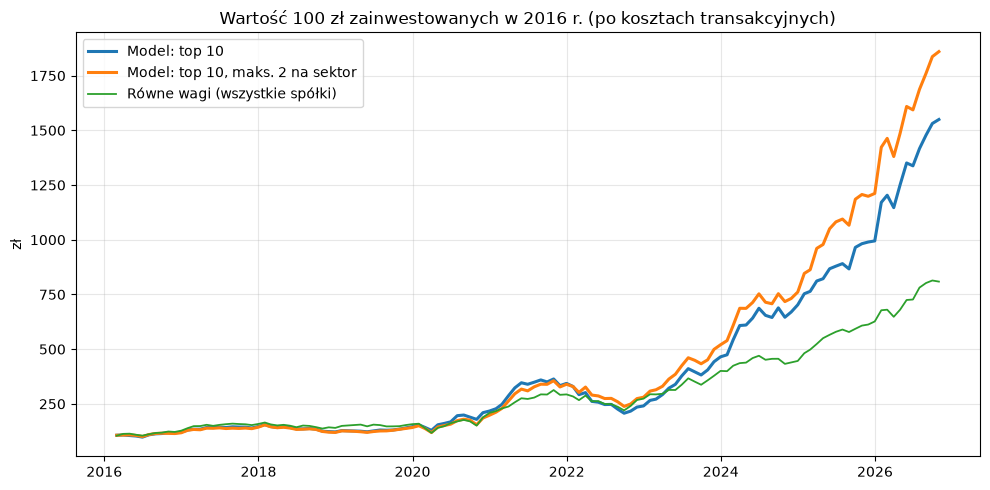

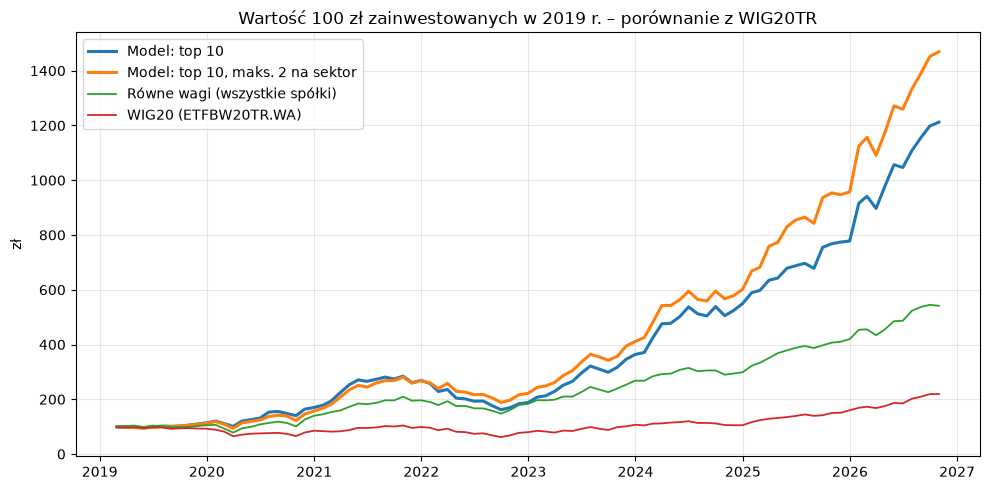

In [ ]:
figures = Path.cwd().parent.parent / "docs" / "figures"
figures.mkdir(parents=True, exist_ok=True)


def equity_chart(df: pd.DataFrame, title: str, filename: str) -> None:
    fig, ax = plt.subplots(figsize=(10, 5))
    for name in df.columns:
        ax.plot(100 * (1 + df[name]).cumprod(), label=name,
                linewidth=2.2 if name.startswith("Model") else 1.3)
    ax.set_title(title)
    ax.set_ylabel("zł")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(figures / filename, dpi=200)
    plt.show()


equity_chart(net.drop(columns=benchmark_cols),
             "Wartość 100 zł zainwestowanych w 2016 r. (po kosztach transakcyjnych)",
             "backtest_equity_full.png")
equity_chart(common,
             f"Wartość 100 zł zainwestowanych w {common.index.min():%Y} r. – porównanie z WIG20TR",
             "backtest_equity_vs_wig20.png")